In [29]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [30]:
class AgentState(TypedDict):
    number1: int
    operator1: str
    number2: int
    operator2: str
    number3: int
    number4: int
    final1: int
    final2: int

In [31]:
def adder1(state: AgentState) -> AgentState:
    state["final1"] = state["number1"] + state["number2"]
    return state

def subtractor1(state: AgentState) -> AgentState:
    state["final1"] = state["number1"] - state["number2"]
    return state    

def multiplier1(state: AgentState) -> AgentState:
    state["final1"] = state["number1"] * state["number2"]
    return state

def divider1(state: AgentState) -> AgentState:
    state["final1"] = state["number1"] / state["number2"]
    return state

def adder2(state: AgentState) -> AgentState:
    state["final2"] = state["number3"] + state["number4"]
    return state

def subtractor2(state: AgentState) -> AgentState:
    state["final2"] = state["number3"] - state["number4"]
    return state

def multiplier2(state: AgentState) -> AgentState:
    state["final2"] = state["number3"] * state["number4"]
    return state

def divider2(state: AgentState) -> AgentState:
    state["final2"] = state["number3"] / state["number4"]
    return state

def operator1_router(state: AgentState) -> str:
    if state["operator1"] == "add":
        return "adder1"
    elif state["operator1"] == "subtract":
        return "subtractor1"
    elif state["operator1"] == "multiply":
        return "multiplier1"
    elif state["operator1"] == "divide":
        return "divider1"
    else:
        raise ValueError("Unknown operation")

def operator2_router(state: AgentState) -> str:
    if state["operator2"] == "add":
        return "adder2"
    elif state["operator2"] == "subtract":
        return "subtractor2"
    elif state["operator2"] == "multiply":
        return "multiplier2"
    elif state["operator2"] == "divide":
        return "divider2"
    else:
        raise ValueError("Unknown operation")

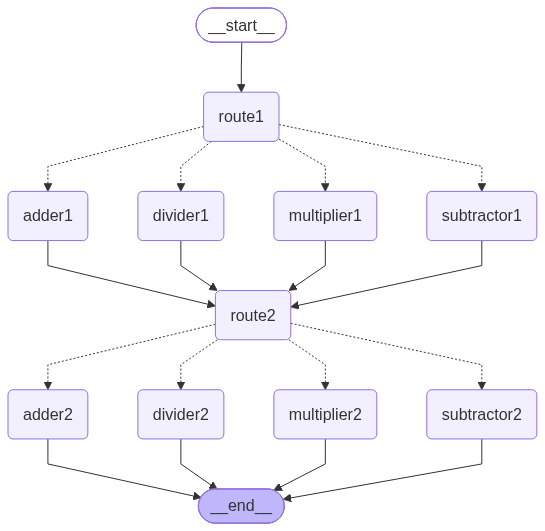

In [32]:
agent = StateGraph(AgentState)
agent.add_node("adder1", adder1)
agent.add_node("subtractor1", subtractor1)
agent.add_node("multiplier1", multiplier1)
agent.add_node("divider1", divider1)
agent.add_node("adder2", adder2)
agent.add_node("subtractor2", subtractor2)
agent.add_node("multiplier2", multiplier2)
agent.add_node("divider2", divider2)
agent.add_node("route1", lambda state:state)
agent.add_node("route2", lambda state:state)

agent.add_edge(START, "route1")
agent.add_conditional_edges("route1", operator1_router, {
    "adder1": "adder1",
    "subtractor1": "subtractor1",
    "multiplier1": "multiplier1",
    "divider1": "divider1"
})

agent.add_edge("adder1", "route2")
agent.add_edge("subtractor1", "route2")
agent.add_edge("multiplier1", "route2")
agent.add_edge("divider1", "route2")
agent.add_conditional_edges("route2", operator2_router, {
    "adder2": "adder2",
    "subtractor2": "subtractor2",
    "multiplier2": "multiplier2",
    "divider2": "divider2"
})

agent.add_edge("adder1", "route2") 
agent.add_edge("subtractor1", "route2") 
agent.add_edge("multiplier1", "route2") 
agent.add_edge("divider1", "route2") 
agent.add_edge("adder2",END) 
agent.add_edge("subtractor2",END) 
agent.add_edge("multiplier2",END) 
agent.add_edge("divider2",END)

app = agent.compile()
from IPython.display import display
display(app)

In [41]:
res = AgentState(number1=6,operator1="add",number2=3,  operator2="multiply",number3=10, number4=2,)
print(app.invoke(res))

{'number1': 6, 'operator1': 'add', 'number2': 3, 'operator2': 'multiply', 'number3': 10, 'number4': 2, 'final1': 9, 'final2': 20}
